# Demo: recovering a lost phase with two dispersions

**In plain words.** A detector sees only intensity, |E|², so the phase is gone. Pass the signal through two known, different dispersions, D1 and D2, and measure the intensity after each. Dispersion mixes phase into intensity in two different ways, so together the two measurements pin the phase down. Gerchberg-Saxton then goes back and forth between them, keeping each measured intensity and updating the phase, until both agree.

The test signal is a QPSK waveform: constant amplitude, phase jumping between four values. The measurements are **simulated** (25 dB SNR, fixed seed), not lab data.

In [1]:
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT / 'dgs'))
import gs_core as gs
import materials as M

wp = gs.make_qpsk_measurements(n_symbols=64, sps=8, D1=-5000.0, D2=-5750.0, snr_db=25.0, rng_seed=0)
phi_rec, err = gs.retrieve_phase(wp['I1'], wp['I2'], wp['D1'], wp['D2'], n_iter=60, unit_amplitude=True)

def align(phi_r, phi_t):
    # the measurements cannot tell a constant phase offset or a sign flip, so remove both before comparing
    best = None
    for s in (1, -1):
        off = np.angle(np.sum(np.exp(1j*(phi_t - s*phi_r))))
        aligned = np.angle(np.exp(1j*(s*phi_r + off)))
        rms = np.sqrt(np.mean(np.angle(np.exp(1j*(phi_t - aligned)))**2))
        if best is None or rms < best[0]: best = (rms, aligned)
    return best
rms, phi_aligned = align(phi_rec, wp['phi_true'])
print(f'recovered phase RMS error: {rms:.3f} rad over {len(phi_rec)} samples')
print(f'for scale, fused silica at 1550 nm has beta2 = {float(M.beta2("fused_silica", 1.55)):.2f} ps^2/km (dgs/materials.py)')

recovered phase RMS error: 0.061 rad over 512 samples
for scale, fused silica at 1550 nm has beta2 = -27.95 ps^2/km (dgs/materials.py)


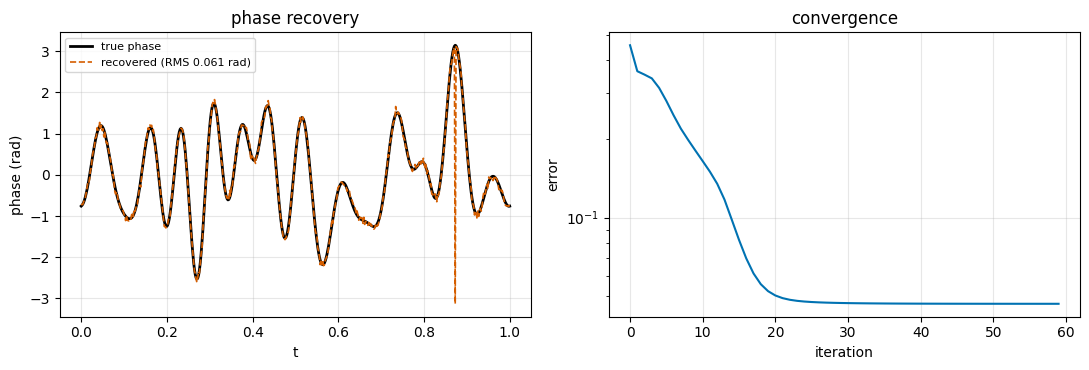

Figure: left, the true QPSK phase (solid black, four levels) and the recovered phase (dashed orange) over time;
right, the algorithm's error on a log scale as the iterations proceed.


In [2]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
a1.plot(wp['t'], wp['phi_true'], color='#000000', lw=2, ls='-', label='true phase')
a1.plot(wp['t'], phi_aligned, color='#D55E00', lw=1.2, ls='--', label=f'recovered (RMS {rms:.3f} rad)')
a1.set_xlabel('t'); a1.set_ylabel('phase (rad)'); a1.set_title('phase recovery'); a1.legend(fontsize=8); a1.grid(alpha=0.3)
a2.semilogy(err, color='#0072B2', ls='-')
a2.set_xlabel('iteration'); a2.set_ylabel('error'); a2.set_title('convergence'); a2.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print('Figure: left, the true QPSK phase (solid black, four levels) and the recovered phase (dashed orange) over time;')
print('right, the algorithm\'s error on a log scale as the iterations proceed.')